# Predicting Airfoil Self-Noise Using Deep Neural Networks

## 1. Project Overview

This project investigates the use of a feed-forward neural network to predict airfoil self-noise from aerodynamic measurements.

The problem is formulated as a supervised learning regression task. The model receives five measured aerodynamic characteristics as inputs and predicts the corresponding scaled sound pressure level in decibels (dB).

The project will be developed progressively, beginning with data exploration and preprocessing before moving into neural-network modelling.

The main concepts examined include:

- Neural-network architecture
- Activation functions
- Forward propagation
- Loss functions
- Backpropagation
- Optimizers
- Learning rate
- Learning curves
- Model comparison and selection

The objective is not simply to obtain a prediction model, but to understand how different neural-network design choices affect its performance on the airfoil self-noise problem.

In [5]:
import sys

print(sys.executable)

c:\Users\Tammy\anaconda3\python.exe


In [6]:
import numpy as np
import tensorflow as tf

print("NumPy:", np.__version__)
print("TensorFlow:", tf.__version__)

NumPy: 1.26.4
TensorFlow: 2.21.0


In [7]:
import sys

sys.path.append("../src")

from loader import load_airfoil_data
from preprocessing import DataPreprocessor
from visualization import (
    plot_feature_distributions,
    plot_target_distribution
)
from models import build_baseline_model
from evaluation import (
    calculate_regression_metrics,
    print_regression_metrics
)

In [8]:
df = load_airfoil_data("../data/raw/airfoil_self_noise.dat")

print(df.shape)
df.head()

(1503, 6)


,frequency_hz,angle_of_attack_deg,chord_length_m,free_stream_velocity_ms,suction_side_displacement_thickness_m,scaled_sound_pressure_db
0,800,0.0,0.3048,71.3,0.002663,126.201
1,1000,0.0,0.3048,71.3,0.002663,125.201
2,1250,0.0,0.3048,71.3,0.002663,125.951
3,1600,0.0,0.3048,71.3,0.002663,127.591
4,2000,0.0,0.3048,71.3,0.002663,127.461


In [9]:
print(df.info())
print("\nMissing values:")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1503 entries, 0 to 1502
Data columns (total 6 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   frequency_hz                           1503 non-null   int64  
 1   angle_of_attack_deg                    1503 non-null   float64
 2   chord_length_m                         1503 non-null   float64
 3   free_stream_velocity_ms                1503 non-null   float64
 4   suction_side_displacement_thickness_m  1503 non-null   float64
 5   scaled_sound_pressure_db               1503 non-null   float64
dtypes: float64(5), int64(1)
memory usage: 70.6 KB
None

Missing values:
frequency_hz                             0
angle_of_attack_deg                      0
chord_length_m                           0
free_stream_velocity_ms                  0
suction_side_displacement_thickness_m    0
scaled_sound_pressure_db                 0
dtype: int64


In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
frequency_hz,1503.0,2886.380572,3152.573137,200.000000,800.000000,1600.000000,4000.000000,20000.000000
angle_of_attack_deg,1503.0,6.782302,5.918128,0.000000,2.000000,5.400000,9.900000,22.200000
chord_length_m,1503.0,0.136548,0.093541,0.025400,0.050800,0.101600,0.228600,0.304800
free_stream_velocity_ms,1503.0,50.860745,15.572784,31.700000,39.600000,39.600000,71.300000,71.300000
suction_side_displacement_thickness_m,1503.0,0.011140,0.013150,0.000401,0.002535,0.004957,0.015576,0.058411
scaled_sound_pressure_db,1503.0,124.835943,6.898657,103.380000,120.191000,125.721000,129.995500,140.987000


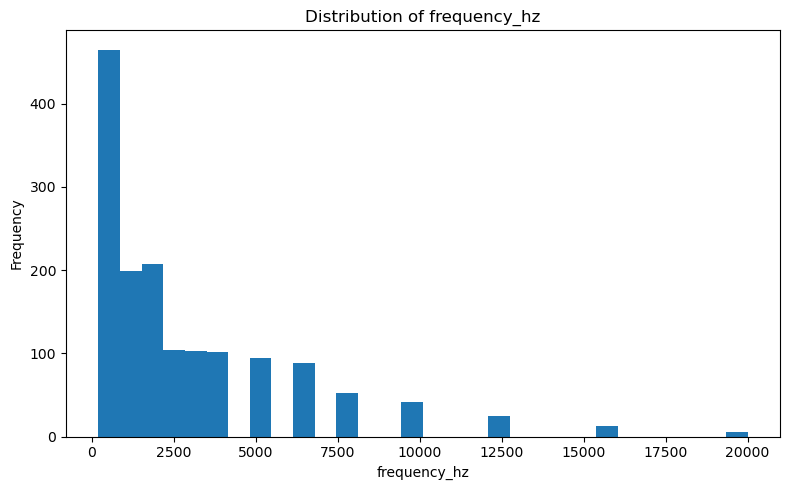

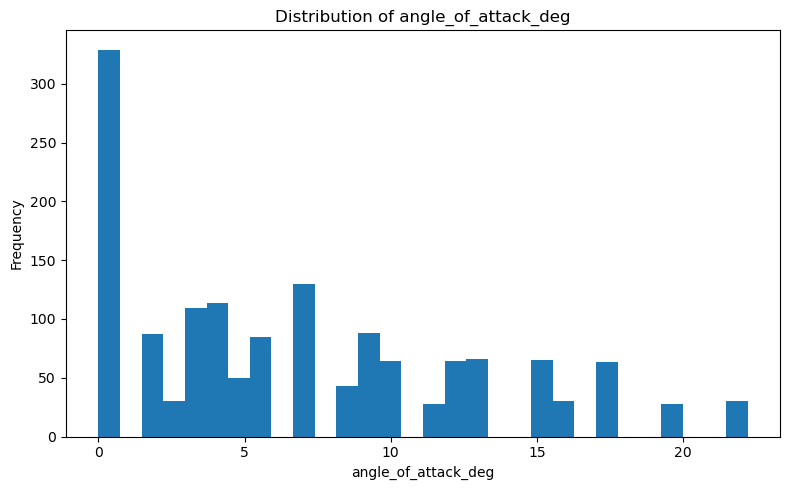

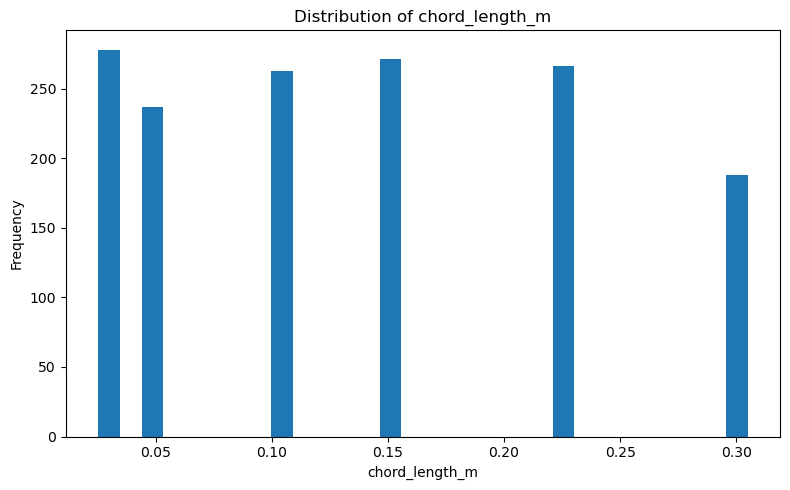

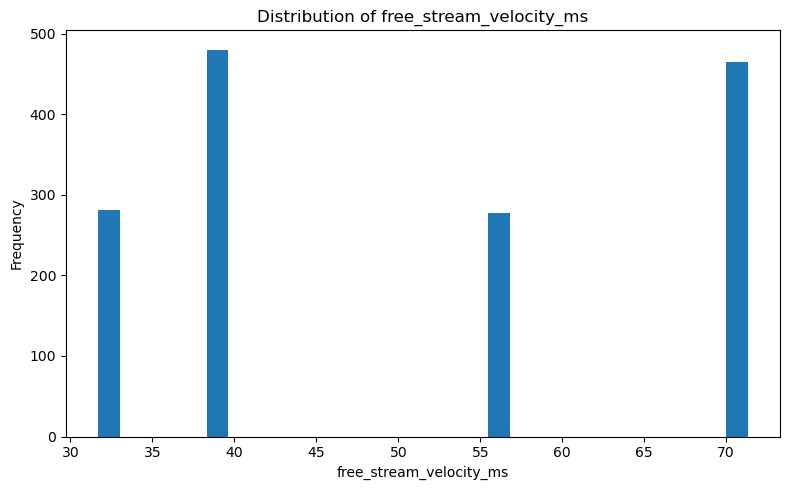

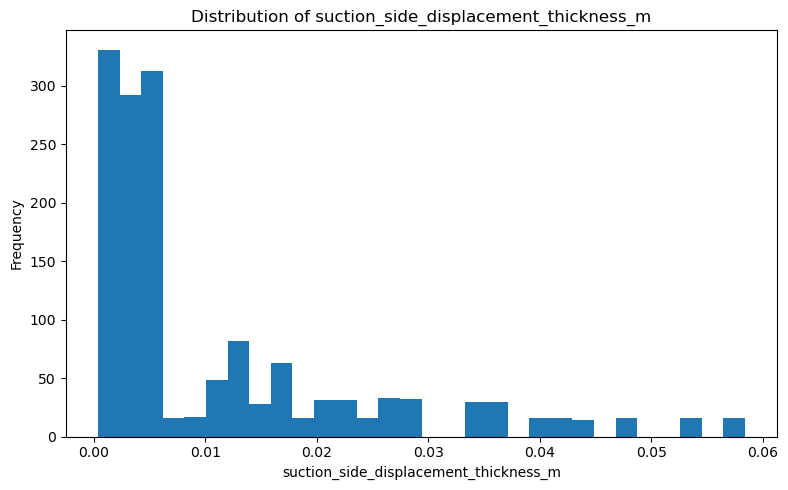

In [11]:
plot_feature_distributions(df, FEATURE_COLUMNS)

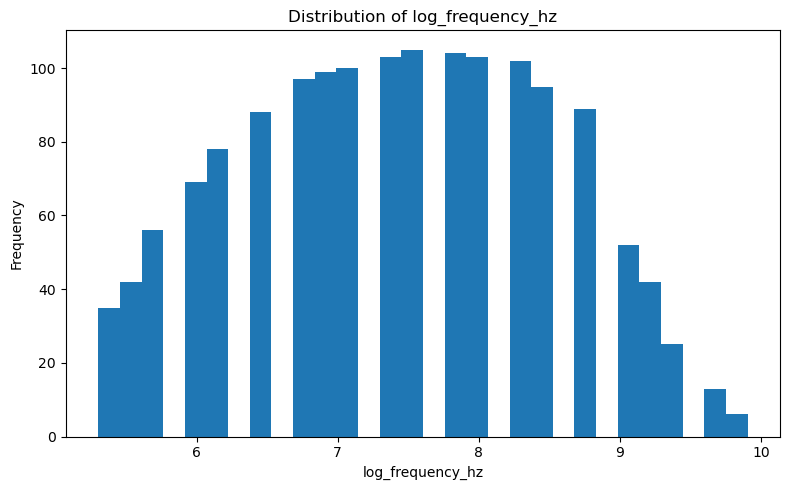

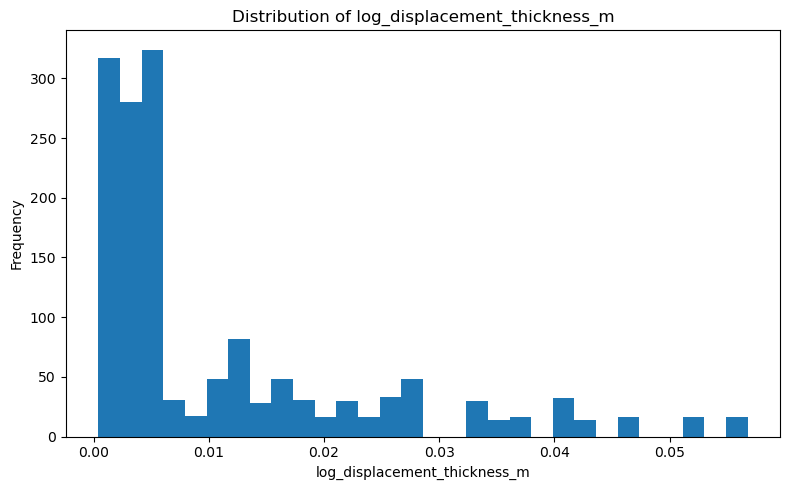

In [12]:
import numpy as np

df["log_frequency_hz"] = np.log1p(df["frequency_hz"])
df["log_displacement_thickness_m"] = np.log1p(
    df["suction_side_displacement_thickness_m"]
)

plot_feature_distributions(
    df,
    ["log_frequency_hz", "log_displacement_thickness_m"]
)

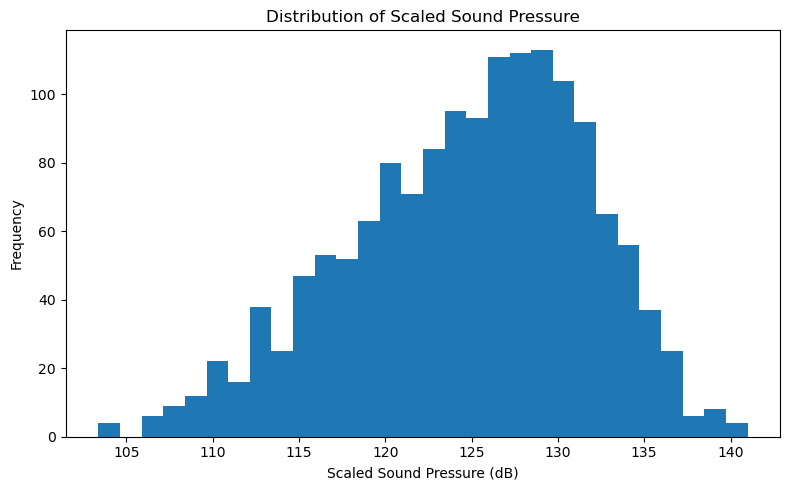

In [13]:
plot_target_distribution(df, TARGET_COLUMN)

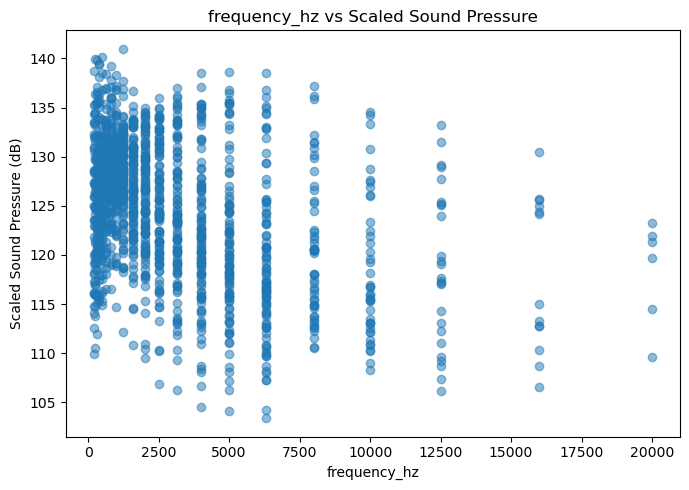

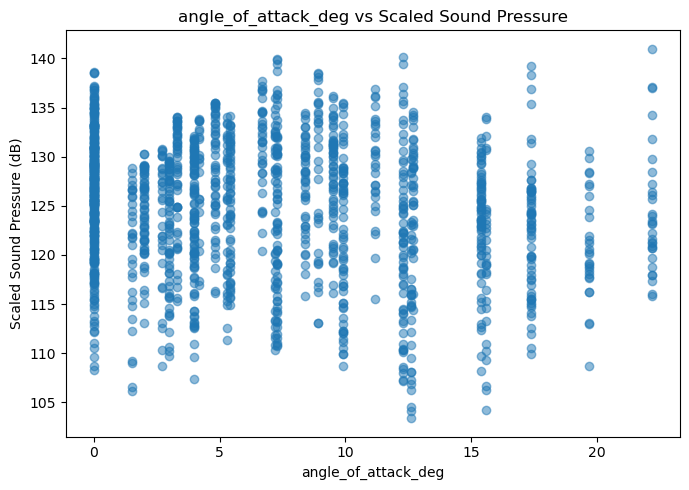

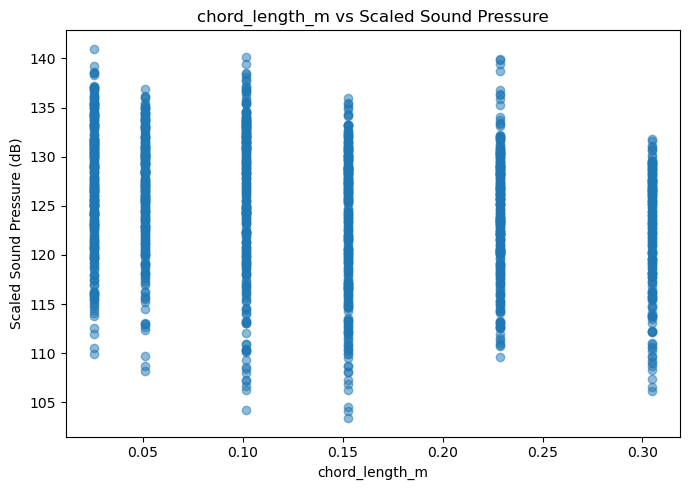

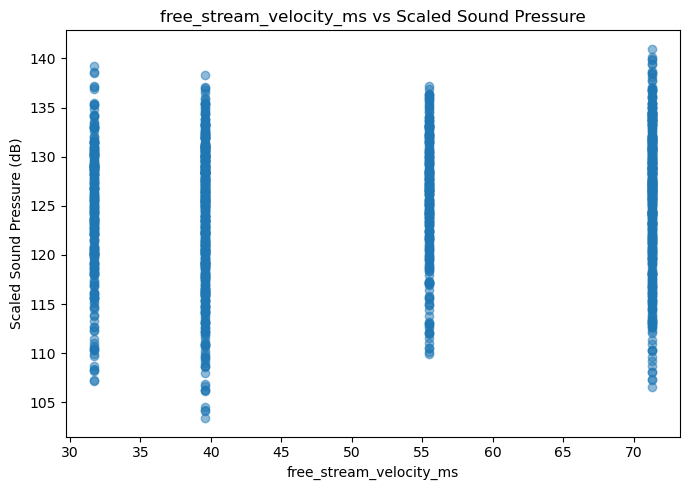

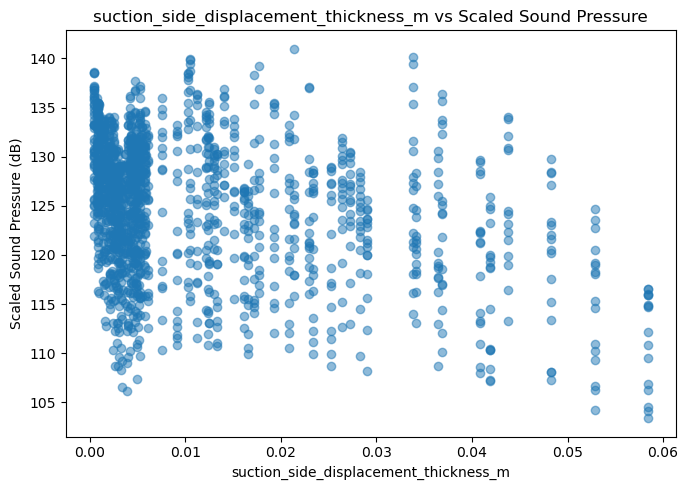

In [14]:
import matplotlib.pyplot as plt

for column in FEATURE_COLUMNS:
    plt.figure(figsize=(7, 5))
    plt.scatter(df[column], df[TARGET_COLUMN], alpha=0.5)
    plt.title(f"{column} vs Scaled Sound Pressure")
    plt.xlabel(column)
    plt.ylabel("Scaled Sound Pressure (dB)")
    plt.tight_layout()
    plt.show()

In [15]:
correlation_matrix = df[FEATURE_COLUMNS + [TARGET_COLUMN]].corr()

correlation_matrix

,frequency_hz,angle_of_attack_deg,chord_length_m,free_stream_velocity_ms,suction_side_displacement_thickness_m,scaled_sound_pressure_db
frequency_hz,1.000000,-0.272765,-0.003661,0.133664,-0.230107,-0.390711
angle_of_attack_deg,-0.272765,1.000000,-0.504868,0.058760,0.753394,-0.156108
chord_length_m,-0.003661,-0.504868,1.000000,0.003787,-0.220842,-0.236162
free_stream_velocity_ms,0.133664,0.058760,0.003787,1.000000,-0.003974,0.125103
suction_side_displacement_thickness_m,-0.230107,0.753394,-0.220842,-0.003974,1.000000,-0.312670
scaled_sound_pressure_db,-0.390711,-0.156108,-0.236162,0.125103,-0.312670,1.000000


### DATA PREPROCESSING

In [16]:
from preprocessing import DataPreprocessor

preprocessor = DataPreprocessor(
    test_size=0.2,
    random_state=42
)

X, y = preprocessor.split_features_target(df)

X_train, X_test, y_train, y_test = preprocessor.split_data(X, y)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (1202, 5)
Testing features: (301, 5)
Training target: (1202,)
Testing target: (301,)


In [17]:
X_train_scaled, X_test_scaled = preprocessor.scale_features(
    X_train,
    X_test
)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

print("\nTraining means:")
print(X_train_scaled.mean(axis=0))

print("\nTraining standard deviations:")
print(X_train_scaled.std(axis=0))

Scaled training shape: (1202, 5)
Scaled testing shape: (301, 5)

Training means:
[5.91133724e-18 3.54680234e-17 2.86699856e-16 3.04988056e-16
 4.43350293e-18]

Training standard deviations:
[1. 1. 1. 1. 1.]


In [18]:
model = build_baseline_model(X_train_scaled.shape[1])

model.summary()

c:\Users\Tammy\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 737 (2.88 KB)

 Trainable params: 737 (2.88 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    verbose=1
)

Epoch 1/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 15433.2686 - mae: 124.0269 - val_loss: 15295.5430 - val_mae: 123.4789
Epoch 2/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 15104.6484 - mae: 122.6872 - val_loss: 14866.5840 - val_mae: 121.7157
Epoch 3/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 14557.0850 - mae: 120.4216 - val_loss: 14156.7285 - val_mae: 118.7385
Epoch 4/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 13691.4639 - mae: 116.7400 - val_loss: 13082.3457 - val_mae: 114.0741
Epoch 5/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 12419.0635 - mae: 111.0920 - val_loss: 11576.7070 - val_mae: 107.1724
Epoch 6/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 10707.9219 - mae: 102.9790 - val_loss: 9652.2197 - val_mae: 97.5867
Epoch 7/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 8645.2031 - mae: 92.1431 - val_loss: 7474.3701 - val_mae: 85.3681
Epoch 8/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 6429.8730 - mae: 78.8015 - val_loss: 5288